# 02 · Series de tiempo de detecciones de calor — Bolivia
Usa la tabla maestra del notebook 01.

**Qué se cuenta:** detecciones satelitales, no incendios únicos. Cada sensor se analiza **por separado** (no se suman).
**Filtro principal:** `type == 0` y confianza distinta de baja. Se compara con la serie sin filtro de confianza para ver la sensibilidad.

Convención de fechas: se usa la fecha **UTC** para que coincida con los archivos originales y la cobertura. (La hora boliviana está disponible como `acq_date_bo`.)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
DATOS = RAIZ / "DATOS_PROCESADOS"
SERIES = DATOS / "series"
FIGS = DATOS / "figuras"
SERIES.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

cols = ["acq_datetime_utc", "source", "sensor", "platform", "frp_mw", "type", "confidence_class",
        "es_tipo0", "en_filtro_principal", "frp_negativo"]
df = pd.read_parquet(DATOS / "firms_bolivia_armonizado.parquet", columns=cols)
df["fecha"] = df["acq_datetime_utc"].dt.normalize()
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.to_period("M").dt.to_timestamp()
cob = pd.read_csv(DATOS / "cobertura_por_fuente_anio.csv")
print(f"{len(df):,} filas")
cob[cob["cobertura_parcial"]]

8,606,708 filas


,source,anio_utc,primer_dia,ultimo_dia,dias_cubiertos,dias_anio,fraccion_anio,cobertura_parcial
0,MODIS-Aqua,2002,2002-07-04,2002-12-31,181,365,0.496,True
24,MODIS-Terra,2000,2000-11-01,2000-12-31,61,366,0.167,True
50,VIIRS-NOAA-20,2018,2018-04-01,2018-12-31,275,365,0.753,True
58,VIIRS-Suomi-NPP,2012,2012-01-20,2012-12-31,347,366,0.948,True


## 1. Series agregadas
Para cada fuente: detecciones, suma de FRP, mediana de FRP y días con detecciones. Se calculan con el filtro principal y, como contraste, solo con `type == 0` (incluye confianza baja).

In [2]:
def agregar(d, clave):
    g = d.groupby(["source", clave])
    return g.agg(detecciones=("frp_mw", "size"),
                 frp_suma_mw=("frp_mw", "sum"),
                 frp_mediana_mw=("frp_mw", "median"),
                 dias_con_deteccion=("fecha", "nunique")).reset_index()

principal = df[df["en_filtro_principal"]]
solo_tipo0 = df[df["es_tipo0"]]

anual = agregar(principal, "anio").merge(cob[["source", "anio_utc", "fraccion_anio", "cobertura_parcial"]],
                                         left_on=["source", "anio"], right_on=["source", "anio_utc"]).drop(columns="anio_utc")
anual_sin_filtro_conf = agregar(solo_tipo0, "anio")
mensual = agregar(principal, "mes")
diario = agregar(principal, "fecha")

anual.to_csv(SERIES / "anual_filtro_principal.csv", index=False)
anual_sin_filtro_conf.to_csv(SERIES / "anual_solo_tipo0.csv", index=False)
mensual.to_csv(SERIES / "mensual_filtro_principal.csv", index=False)
diario.to_csv(SERIES / "diario_filtro_principal.csv", index=False)
anual.pivot(index="anio", columns="source", values="detecciones")

source,MODIS-Aqua,MODIS-Terra,VIIRS-NOAA-20,VIIRS-Suomi-NPP
anio,,,,
2000,NaN,758.0,NaN,NaN
2001,NaN,13433.0,NaN,NaN
2002,40189.0,22320.0,NaN,NaN
2003,36817.0,14613.0,NaN,NaN
2004,64361.0,33249.0,NaN,NaN
2005,56083.0,28517.0,NaN,NaN
2006,45871.0,21753.0,NaN,NaN
2007,67122.0,32747.0,NaN,NaN
2008,44126.0,23625.0,NaN,NaN


## 2. Serie anual por fuente
Los puntos huecos son años con cobertura parcial (no comparables con años completos).

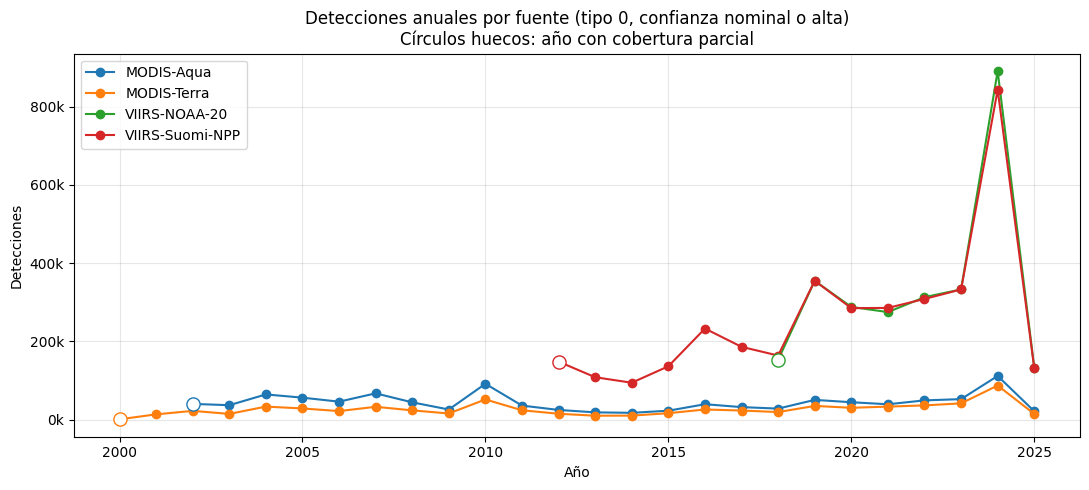

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
for fuente, g in anual.groupby("source"):
    g = g.sort_values("anio")
    linea, = ax.plot(g["anio"], g["detecciones"], marker="o", label=fuente)
    parcial = g[g["cobertura_parcial"]]
    ax.scatter(parcial["anio"], parcial["detecciones"], s=90, facecolors="white", edgecolors=linea.get_color(), zorder=5)
ax.set_title("Detecciones anuales por fuente (tipo 0, confianza nominal o alta)\nCírculos huecos: año con cobertura parcial")
ax.set_xlabel("Año"); ax.set_ylabel("Detecciones")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "anual_por_fuente.png", dpi=150); plt.show()

## 3. Sensibilidad al filtro de confianza
¿Cuánto cambia la serie si se incluye la confianza baja? Se muestra el % de detecciones que se pierde por año.

In [4]:
sens = anual[["source", "anio", "detecciones"]].merge(
    anual_sin_filtro_conf[["source", "anio", "detecciones"]], on=["source", "anio"], suffixes=("_filtrado", "_tipo0"))
sens["perdida_pct"] = (100 * (1 - sens["detecciones_filtrado"] / sens["detecciones_tipo0"])).round(1)
sens.to_csv(SERIES / "sensibilidad_confianza.csv", index=False)
print(sens.pivot(index="anio", columns="source", values="perdida_pct").round(1).to_string())

source  MODIS-Aqua  MODIS-Terra  VIIRS-NOAA-20  VIIRS-Suomi-NPP
anio                                                           
2000           NaN          5.8            NaN              NaN
2001           NaN          4.9            NaN              NaN
2002           4.2          5.2            NaN              NaN
2003           3.9          5.2            NaN              NaN
2004           4.7          7.2            NaN              NaN
2005           4.4          5.6            NaN              NaN
2006           4.1          5.6            NaN              NaN
2007           4.5          6.4            NaN              NaN
2008           3.8          5.2            NaN              NaN
2009           4.0          4.7            NaN              NaN
2010           4.7          6.5            NaN              NaN
2011           4.8          6.1            NaN              NaN
2012           4.3          5.6            NaN              6.8
2013           3.9          4.8         

## 4. Ciclo estacional (calendario de actividad)
Detecciones por mes y año, una fuente por panel. Muestra la temporada de quemas de Bolivia (aprox. julio–octubre).

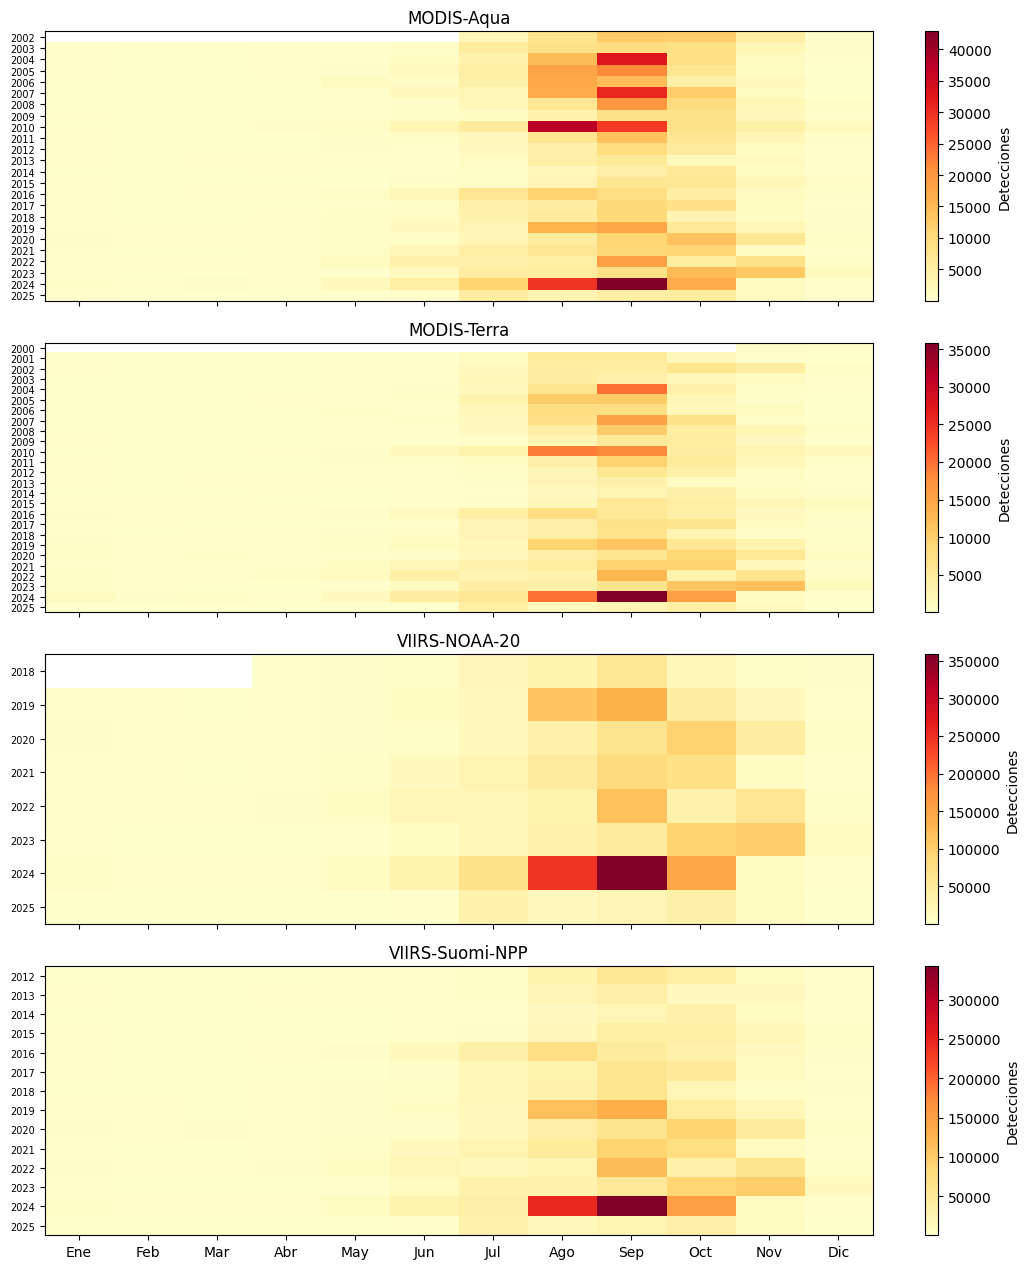

In [5]:
fuentes = sorted(df["source"].unique())
fig, axes = plt.subplots(len(fuentes), 1, figsize=(11, 3.2 * len(fuentes)), sharex=True)
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for ax, fuente in zip(axes, fuentes):
    m = mensual[mensual["source"] == fuente].copy()
    m["anio"] = m["mes"].dt.year; m["m"] = m["mes"].dt.month
    tabla = m.pivot(index="anio", columns="m", values="detecciones").reindex(columns=range(1, 13))
    im = ax.imshow(tabla.values, aspect="auto", cmap="YlOrRd")
    ax.set_yticks(range(len(tabla.index))); ax.set_yticklabels(tabla.index, fontsize=7)
    ax.set_xticks(range(12)); ax.set_xticklabels(meses)
    ax.set_title(fuente); fig.colorbar(im, ax=ax, label="Detecciones")
fig.tight_layout(); fig.savefig(FIGS / "calendario_mensual.png", dpi=150); plt.show()

## 5. Serie mensual y estacionalidad promedio

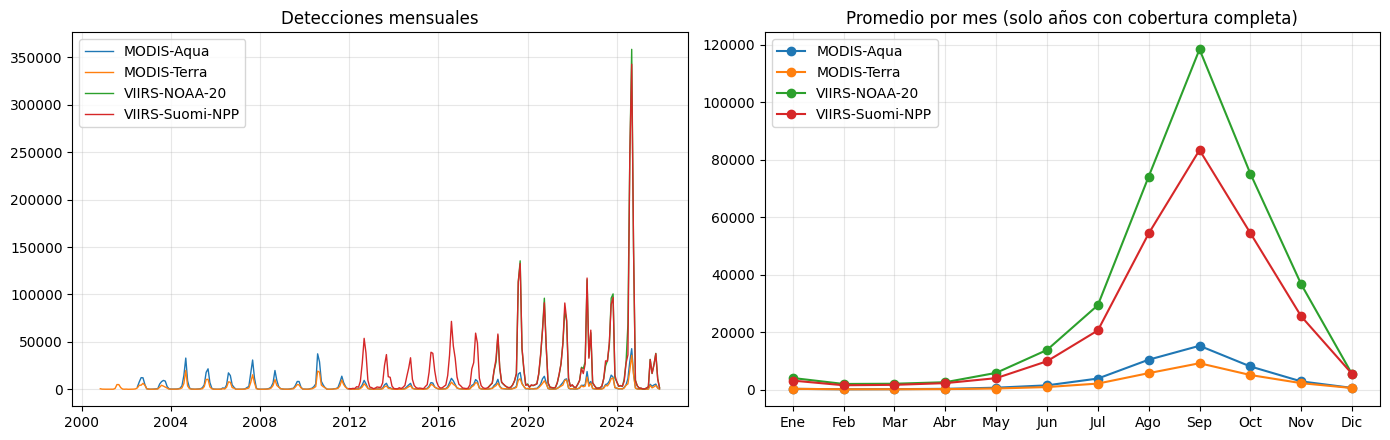

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for fuente, g in mensual.groupby("source"):
    axes[0].plot(g["mes"], g["detecciones"], label=fuente, lw=1)
axes[0].set_title("Detecciones mensuales"); axes[0].grid(alpha=0.3); axes[0].legend()

# promedio por mes solo con años de cobertura completa
completos = cob[~cob["cobertura_parcial"]][["source", "anio_utc"]]
mm = mensual.assign(anio=mensual["mes"].dt.year, m=mensual["mes"].dt.month).merge(
    completos, left_on=["source", "anio"], right_on=["source", "anio_utc"])
for fuente, g in mm.groupby("source"):
    prom = g.groupby("m")["detecciones"].mean().reindex(range(1, 13))
    axes[1].plot(range(1, 13), prom.values, marker="o", label=fuente)
axes[1].set_xticks(range(1, 13)); axes[1].set_xticklabels(meses)
axes[1].set_title("Promedio por mes (solo años con cobertura completa)"); axes[1].grid(alpha=0.3); axes[1].legend()
fig.tight_layout(); fig.savefig(FIGS / "mensual_y_estacionalidad.png", dpi=150); plt.show()

## 6. Diagnóstico para la armonización MODIS ↔ VIIRS
Esto **no armoniza todavía**: mide qué tan distintas son las series en el periodo en que coinciden (2012–2025) y si la relación es estable. Es la base para decidir el método del notebook de armonización (factor de escala, regresión, etc.).

Se compara MODIS (Terra+Aqua) contra VIIRS S-NPP, mes a mes, solo con meses de cobertura completa de ambas.

Correlación mensual MODIS vs S-NPP: 0.988
Razón VIIRS/MODIS: mediana 3.65 | p10 3.2 | p90 4.56


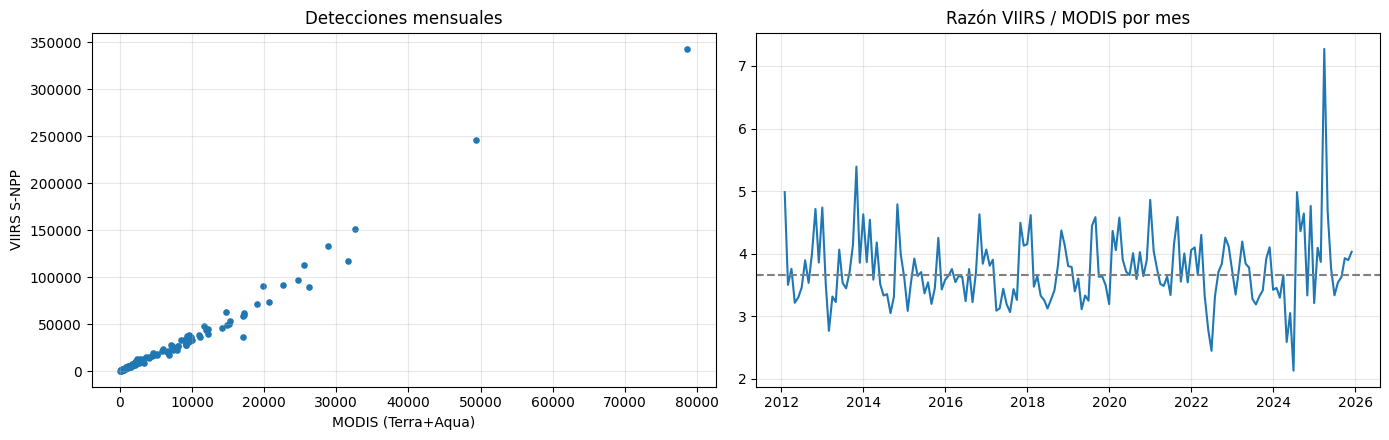

In [7]:
comp = mensual.copy()
comp["anio"] = comp["mes"].dt.year
comp = comp[comp["anio"] >= 2012]
modis = comp[comp["source"].str.startswith("MODIS")].groupby("mes")["detecciones"].sum().rename("modis")
snpp = comp[comp["source"] == "VIIRS-Suomi-NPP"].set_index("mes")["detecciones"].rename("snpp")
ratio = pd.concat([modis, snpp], axis=1).dropna()
ratio = ratio[ratio.index >= "2012-02-01"]   # S-NPP empieza el 20-ene-2012
ratio["viirs_por_modis"] = ratio["snpp"] / ratio["modis"]
ratio.to_csv(SERIES / "ratio_viirs_modis_mensual.csv")

print("Correlación mensual MODIS vs S-NPP:", round(ratio["modis"].corr(ratio["snpp"]), 3))
print("Razón VIIRS/MODIS: mediana", round(ratio["viirs_por_modis"].median(), 2),
      "| p10", round(ratio["viirs_por_modis"].quantile(.1), 2), "| p90", round(ratio["viirs_por_modis"].quantile(.9), 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(ratio["modis"], ratio["snpp"], s=14)
axes[0].set_xlabel("MODIS (Terra+Aqua)"); axes[0].set_ylabel("VIIRS S-NPP"); axes[0].set_title("Detecciones mensuales"); axes[0].grid(alpha=0.3)
axes[1].plot(ratio.index, ratio["viirs_por_modis"]); axes[1].axhline(ratio["viirs_por_modis"].median(), ls="--", c="gray")
axes[1].set_title("Razón VIIRS / MODIS por mes"); axes[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "diagnostico_modis_viirs.png", dpi=150); plt.show()

In [8]:
# ¿La razón es estable entre años? (si no lo es, un factor único no sirve)
r_anual = ratio.groupby(ratio.index.year).agg(modis=("modis", "sum"), snpp=("snpp", "sum"))
r_anual["viirs_por_modis"] = (r_anual["snpp"] / r_anual["modis"]).round(2)
r_anual

,modis,snpp,viirs_por_modis
mes,,,
2012,39099,147387,3.77
2013,28484,108282,3.80
2014,27563,94256,3.42
2015,39133,136262,3.48
2016,65202,232645,3.57
2017,55186,185967,3.37
2018,47391,163682,3.45
2019,85401,354828,4.15
2020,74608,284862,3.82


## 7. Cómo leer estos resultados
- Una fila es una **detección**, no un incendio. No se deben sumar fuentes.
- MODIS 2000/2002 y VIIRS S-NPP 2012 / NOAA-20 2018 tienen cobertura parcial (círculos huecos).
- MODIS cambia de versión de procesamiento en 2018 (6.03) y 2023 (61.03). Si el cociente VIIRS/MODIS cambia justo en esos años, revisar antes de armonizar.
- La razón VIIRS/MODIS varía mucho entre meses y años: cuando hay poco fuego domina VIIRS (detecta fuegos más pequeños). Eso es lo que debe resolver el notebook de armonización.